In [5]:
import numpy as np
import matplotlib.pyplot as plt

def convolucao_linear(x1_n, x2_n, N):

    # Zero-padding dos sinais x1_n e x2_n para ter N amostras:
    x1_n_pad = np.pad(x1_n, (0, N - len(x1_n)), 'constant')
    x2_n_pad = np.pad(x2_n, (0, N - len(x2_n)), 'constant')

    # Cálculo da DFT dos sinais x1_n e x2_n
    X1_k = DFT(x1_n_pad, N)
    X2_k = DFT(x2_n_pad, N)

    # Multiplicação ponto a ponto das DFTs
    Y_k = X1_k * X2_k

    # Cálculo da IDFT do resultado
    y_n = IDFT(Y_k, N)

    return y_n

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)

def DFT(x_n, N):

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def IDFT(X_k, N):
    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da IDFT
    x_n = np.zeros(N, dtype=complex)
    for n in range(N):
        x_n[n] = np.sum( np.conj(W_n[:,n]) * X_k ) / N

    return x_n

def convolucao_circular(x1_n, x2_n, N):
    y_n = np.zeros(N, dtype=complex)
    for n in range(N):
        for m in range(N):
            y_n[n] += x1_n[m] * x2_n[(n - m) % N]
    return y_n

c:\Users\Cliente\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Cliente\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\ma\core.py:3452: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval
c:\Users\Cliente\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


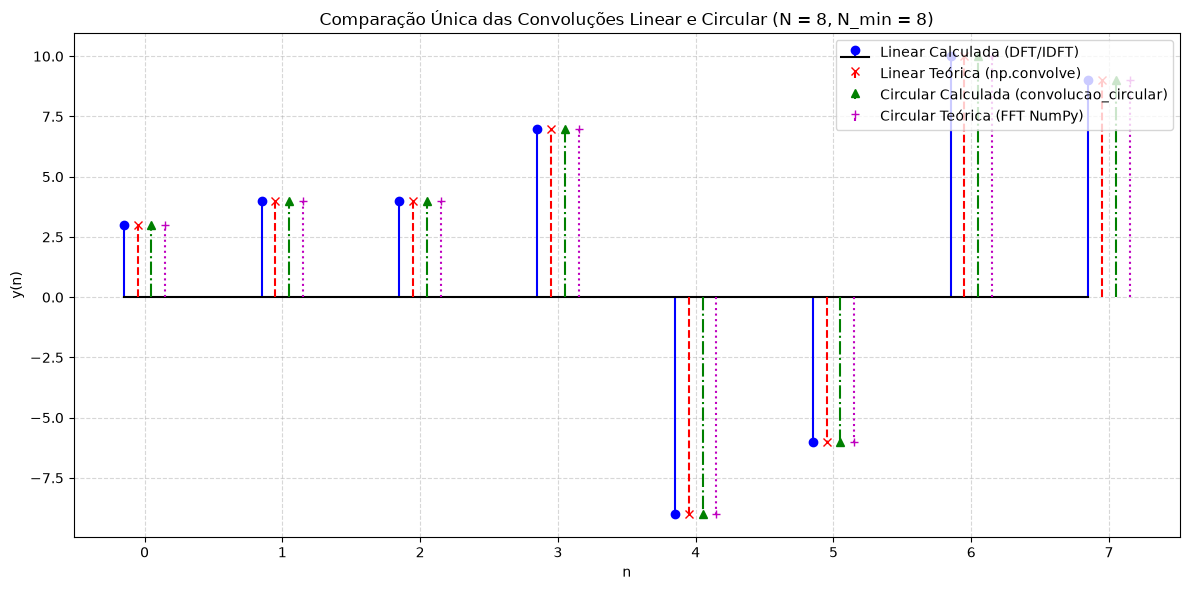

In [ ]:
# ----------- SINAIS PARA TESTES -----------
# 1. Sinais pré-definidos
x1_n = np.array([2, 0, -1, 5, 4, -3, 2], dtype=float)
x2_n = np.array([1, -2, 3, 0], dtype=float)

# 2. Sinais aleatórios (PARA TESTES ADICIONAIS, DESCOMENTAR AS LINHAS ABAIXO)
# L1 = 3
# L2 = 5
# x1_n = np.random.rand(L1) + 1j * np.random.rand(L1)
# x2_n = np.random.rand(L2) + 1j * np.random.rand(L2)

# Tamanho mínimo para não haver aliasing temporal (N_min = L1 + L2 - 1)
N_min = len(x1_n) + len(x2_n) - 1
N = N_min

# 1. Convolução Linear calculada via DFT/IDFT com padding correto (N >= N_min)
y_n_linear = convolucao_linear(x1_n, x2_n, N)

# 2. Convolução Circular com preenchimento prévio dos sinais até ao tamanho N
x1_n_pad = np.pad(x1_n, (0, N - len(x1_n)), 'constant')
x2_n_pad = np.pad(x2_n, (0, N - len(x2_n)), 'constant')
y_n_circular = convolucao_circular(x1_n_pad, x2_n_pad, N)

# 3. Convolução Linear Teórica (nativa do NumPy)
yn_linear_teo = np.pad(np.convolve(x1_n, x2_n), (0, max(0, N - N_min)))[:N]

# 4. Convolução Circular Teórica (nativa do NumPy)
yn_circular_teo = np.real(np.fft.ifft(np.fft.fft(x1_n, N) * np.fft.fft(x2_n, N)))

# GRÁFICO COMPARATIVO DAS CONVOLUÇÕES LINEAR E CIRCULAR:

plt.figure(figsize=(12, 6))

n = np.arange(N)

# 1. Linear Calculada
plt.stem(n - 0.15, np.real(y_n_linear), linefmt='b-', markerfmt='bo', basefmt='k-', label='Linear Calculada (DFT/IDFT)')

# 2. Linear Teórica
plt.stem(n - 0.05, yn_linear_teo, linefmt='r--', markerfmt='rx', basefmt='none', label='Linear Teórica (np.convolve)')

# 3. Circular Calculada
plt.stem(n + 0.05, np.real(y_n_circular), linefmt='g-.', markerfmt='g^', basefmt='none', label='Circular Calculada (convolucao_circular)')

# 4. Circular Teórica
plt.stem(n + 0.15, yn_circular_teo, linefmt='m:', markerfmt='m+', basefmt='none', label='Circular Teórica (FFT NumPy)')

plt.title(f'Comparação Única das Convoluções Linear e Circular (N = {N}, N_min = {N_min})')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()